In [1]:
# =============================================================================
# CELL 0 — imports
# =============================================================================
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import quad
from scipy.special import gammaln
from scipy.optimize import brentq
from time import time

FIGDIR = "images"          # where figures are written
import os; os.makedirs(FIGDIR, exist_ok=True)

In [2]:
# =============================================================================
# CELL 1 — log A_n(z) = log E[exp(z R_n)],  R_n ~ chi_n
# Peak-centred, log-space quadrature.  Verified against 60-digit mpmath to
# ~1e-12 for n up to 300 and z in [-8, 12].
# =============================================================================
def log_A_n_quad(z, n):
    """log A_n(z) by stable numerical integration."""
    z = float(z)
    r_star = (z + np.sqrt(z * z + 4.0 * (n - 1))) / 2.0
    r_star = max(r_star, 1e-300)
    log_max = (n - 1) * np.log(r_star) - 0.5 * (r_star - z) ** 2

    def integrand(r):
        if r <= 0.0:
            return 0.0
        return np.exp((n - 1) * np.log(r) - 0.5 * (r - z) ** 2 - log_max)

    integral, _ = quad(integrand, 0.0, np.inf, limit=200)
    return (0.5 * z * z
            - (0.5 * n - 1) * np.log(2)
            - gammaln(0.5 * n)
            + log_max
            + np.log(integral))


def make_log_A_n_table(n, z_max=12.0, num_points=601):
    z_grid = np.linspace(-z_max, z_max, num_points)
    log_A_grid = np.array([log_A_n_quad(z, n) for z in z_grid])
    return z_grid, log_A_grid


def logAn_lookup(z, n, z_grid, log_A_grid):
    z = float(z)
    zmax = z_grid[-1]
    if -zmax <= z <= zmax:
        return float(np.interp(z, z_grid, log_A_grid))
    return log_A_n_quad(z, n)          # exact outside the table

In [3]:
# =============================================================================
# CELL 2 — prior log densities
# Scales are EXPLICIT so that the paper text and the code cannot drift apart.
# Set CAUCHY_SCALE = 1/np.sqrt(2) for the Rouder-JZS default.
# =============================================================================
CAUCHY_SCALE = 1.0        # <-- set to 1/np.sqrt(2) for Rouder--JZS
T5_SCALE     = 1.0
GAUSS_SCALE  = 1.0
LAPLACE_SCALE = 1.0       # supplement only


def log_pi_gauss(theta, s=GAUSS_SCALE):
    return -0.5 * np.log(2.0 * np.pi) - np.log(s) - 0.5 * (theta / s) ** 2


def log_pi_cauchy(theta, r=CAUCHY_SCALE):
    return -np.log(np.pi * r) - np.log1p((theta / r) ** 2)


def log_pi_t5(theta, r=T5_SCALE):
    nu = 5.0
    return (gammaln((nu + 1.0) / 2.0) - gammaln(nu / 2.0)
            - 0.5 * np.log(nu * np.pi) - np.log(r)
            - 0.5 * (nu + 1.0) * np.log1p((theta / r) ** 2 / nu))


def log_pi_laplace(theta, b=LAPLACE_SCALE):        # supplement only
    return -np.log(2.0 * b) - np.abs(theta) / b


# --- MAIN PAPER: Cauchy, Gaussian, Student-t5 only -------------------------
PRIOR_LOG_PDFS = {
    "Cauchy":     log_pi_cauchy,
    "Gaussian":   log_pi_gauss,
    "Student-$t_5$": log_pi_t5,
}
PRIOR_COLORS = {
    "Cauchy":     "tab:red",
    "Gaussian":   "tab:blue",
    "Student-$t_5$": "tab:orange",
}

# --- SUPPLEMENT: adds Laplace ----------------------------------------------
PRIOR_LOG_PDFS_SUPP = dict(PRIOR_LOG_PDFS, **{"Laplace": log_pi_laplace})
PRIOR_COLORS_SUPP   = dict(PRIOR_COLORS,   **{"Laplace": "tab:green"})

In [4]:
# =============================================================================
# CELL 3 — Lebesgue benchmark (closed form)
# =============================================================================
def log_M_n_leb(u_n, n):
    return 0.5 * np.log(2.0 * np.pi / n) - 0.5 * n * np.log1p(-u_n * u_n / n)


def g_leb(c):
    """Closed-form Lebesgue calibration at n = 2."""
    c = np.asarray(c, dtype=float)
    a = np.minimum(np.sqrt(np.pi) / c, 1.0)
    val = (2.0 / np.pi) * (np.arcsin(np.sqrt(a))
                           + np.sqrt(a * np.maximum(1.0 - a, 0.0)))
    return np.where(c <= np.sqrt(np.pi), 1.0, val)

In [5]:
# =============================================================================
# CELL 4 — mixture M_n^{Pi_m} by quadrature, and grid precomputation
# FIX: exact fallback when u falls outside the tabulated grid (np.interp would
# otherwise clamp silently and understate the evidence).
# =============================================================================
def log_M_n_quad_single(u, m, n, prior_log_pdf, z_grid_n, log_A_grid_n):
    u = float(u)
    gam = max(n - u * u, 1e-12)
    theta_peak = np.sign(u) * np.sqrt((n - 1.0) / gam)      # integrand peak

    def log_integrand(theta):
        return (-0.5 * n * theta * theta
                + logAn_lookup(theta * u, n, z_grid_n, log_A_grid_n)
                + float(prior_log_pdf(theta - m)))

    log_max_init = max(log_integrand(t) for t in
                       (0.0, float(m), theta_peak, -theta_peak,
                        theta_peak + 1.0, theta_peak - 1.0))

    integrand = lambda theta: np.exp(log_integrand(theta) - log_max_init)

    theta_max = max(20.0, abs(m) + 12.0, abs(theta_peak) + 15.0)
    pts = sorted({p for p in (0.0, float(m), theta_peak, -theta_peak)
                  if -theta_max < p < theta_max})
    integral, _ = quad(integrand, -theta_max, theta_max,
                       limit=400, points=tuple(pts))
    if not np.isfinite(integral) or integral <= 0.0:
        return -np.inf
    return log_max_init + np.log(integral)


def _u_cap(n, z_cap):
    """u at which theta_peak(u) * u equals z_cap."""
    return np.sqrt(z_cap * z_cap * n / ((n - 1) + z_cap * z_cap))


def precompute_log_M_n_on_u_grid(m, n, prior_log_pdf,
                                 z_grid_n, log_A_grid_n, n_u=200):
    sqn = np.sqrt(n)
    umax = min(sqn - 1e-3, _u_cap(n, z_grid_n[-1]))
    if n == 2:                                  # refine boundary for calibration
        core = np.linspace(-umax, umax, n_u)
        edge = umax - np.geomspace(1e-4, 0.05, 40)
        u_grid = np.unique(np.concatenate([core, edge, -edge]))
    else:
        u_grid = np.linspace(-umax, umax, n_u)
    log_M_grid = np.array([
        log_M_n_quad_single(u, m, n, prior_log_pdf, z_grid_n, log_A_grid_n)
        for u in u_grid])
    return u_grid, log_M_grid


def eval_log_M(u_query, u_grid, log_M_grid, m, n,
               prior_log_pdf, z_grid_n, log_A_grid_n):
    """Interpolate on the grid; fall back to exact quadrature outside it."""
    u_query = np.atleast_1d(np.asarray(u_query, dtype=float))
    out = np.interp(u_query, u_grid, log_M_grid)
    outside = (u_query < u_grid[0]) | (u_query > u_grid[-1])
    if np.any(outside):
        for i in np.flatnonzero(outside):
            out[i] = log_M_n_quad_single(u_query[i], m, n, prior_log_pdf,
                                         z_grid_n, log_A_grid_n)
    return out



In [6]:
# =============================================================================
# CELL 5 — u_n statistic and the extended-Ville cutoff
# =============================================================================
def u_n_of(Y):
    return Y.sum(axis=-1) / np.sqrt((Y * Y).sum(axis=-1))


def eville_cutoff_from_samples(M2_samples, alpha):
    """Smallest c with E_0[min(M_2/c, 1)] <= alpha, by bisection."""
    lo = 1e-12
    hi = max(1.0 / alpha, float(np.max(M2_samples)),
             float(M2_samples.mean()) / alpha) * 2.0
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        if float(np.minimum(M2_samples / mid, 1.0).mean()) <= alpha:
            hi = mid
        else:
            lo = mid
    return hi


In [7]:
# =============================================================================
# CELL 6 — setup
# FIX: m_grid now contains theta_star exactly, and is refined near the truth.
# =============================================================================
rng = np.random.default_rng(seed=20260508)

theta_star = 0.5
alpha = 0.10

n_values = [20, 50, 100, 150]

_coarse = np.linspace(-30.0, 30.0, 25)
_fine   = np.array([-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0, 4.0])
m_grid  = np.unique(np.concatenate([_coarse, _fine, [theta_star]]))

B_data = 100 #10_000
B_cal  = 100 #100_000

print("Tabulating log A_n ...")
A_table = {}
for n in [2] + n_values:
    if n not in A_table:
        A_table[n] = make_log_A_n_table(
            n, z_max=(35.0 if n == 2 else 14.0),
            num_points=(1401 if n == 2 else 701))
z_grid_n2, log_A_grid_n2 = A_table[2]
print(f"  done.  |m_grid| = {len(m_grid)}")

Tabulating log A_n ...
  done.  |m_grid| = 32


In [8]:
# =============================================================================
# CELL 7 — calibration: one shared H_0 sample, swept over (prior, m)
# =============================================================================
print("Drawing H_0 calibration sample ...")
Y1c = rng.standard_normal(B_cal)
Y2c = rng.standard_normal(B_cal)
u2c = (Y1c + Y2c) / np.sqrt(Y1c * Y1c + Y2c * Y2c)

print("Computing calibration M_2 samples for each (prior, m) ...")
cal_cutoffs = {}                       # (prior_name, m) -> extended-Ville cutoff
t0 = time()
for prior_name, prior_log_pdf in PRIOR_LOG_PDFS.items():
    for m in m_grid:
        ug, lMg = precompute_log_M_n_on_u_grid(
            m=m, n=2, prior_log_pdf=prior_log_pdf,
            z_grid_n=z_grid_n2, log_A_grid_n=log_A_grid_n2, n_u=200)
        log_M_cal = eval_log_M(u2c, ug, lMg, m, 2, prior_log_pdf,
                               z_grid_n2, log_A_grid_n2)
        M2_cal = np.exp(np.minimum(log_M_cal, 700.0))
        cal_cutoffs[(prior_name, m)] = eville_cutoff_from_samples(M2_cal, alpha)
    print(f"  {prior_name}: {time() - t0:.1f}s")

# Lebesgue extended-Ville cutoff (closed form, no Monte Carlo error)
c_eV_leb = brentq(lambda c: float(g_leb(np.array([c]))[0]) - alpha,
                  np.sqrt(np.pi), 1e8)
print(f"Lebesgue eV cutoff = {c_eV_leb:.4f}   (Ville cutoff = {1/alpha:.1f})")

Drawing H_0 calibration sample ...
Computing calibration M_2 samples for each (prior, m) ...


/var/folders/31/6gx1txds1v51wc6_tdp16jth0000gp/T/ipykernel_58658/2012194725.py:25: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  integral, _ = quad(integrand, -theta_max, theta_max,
/var/folders/31/6gx1txds1v51wc6_tdp16jth0000gp/T/ipykernel_58658/2605514602.py:23: RuntimeWarning: divide by zero encountered in log
  + np.log(integral))
/var/folders/31/6gx1txds1v51wc6_tdp16jth0000gp/T/ipykernel_58658/2012194725.py:25: IntegrationWarning: The maximum number of subdivisions (400) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.


  Cauchy: 133.5s
  Gaussian: 227.9s
  Student-$t_5$: 355.3s
Lebesgue eV cutoff = 286.7471   (Ville cutoff = 10.0)


In [9]:
# =============================================================================
# CELL 8 — MAIN FIGURE 1: power vs prior location m
# FIX: one nested data stream, sliced to each n, so panels are comparable.
# =============================================================================
print("Power sweep ...")
prior_names = list(PRIOR_LOG_PDFS.keys())
n_max = max(n_values)

Y_full = rng.standard_normal((B_data, n_max)) + theta_star   # nested stream
u_data_by_n = {n: u_n_of(Y_full[:, :n]) for n in n_values}

powers_V  = {(p, n): np.zeros_like(m_grid) for p in prior_names for n in n_values}
powers_eV = {(p, n): np.zeros_like(m_grid) for p in prior_names for n in n_values}
leb_baseline = {}

t0 = time()
for n in n_values:
    z_grid_n, log_A_grid_n = A_table[n]
    u_data = u_data_by_n[n]

    for prior_name, prior_log_pdf in PRIOR_LOG_PDFS.items():
        for j, m in enumerate(m_grid):
            ug, lMg = precompute_log_M_n_on_u_grid(
                m=m, n=n, prior_log_pdf=prior_log_pdf,
                z_grid_n=z_grid_n, log_A_grid_n=log_A_grid_n, n_u=200)
            log_M_data = eval_log_M(u_data, ug, lMg, m, n, prior_log_pdf,
                                    z_grid_n, log_A_grid_n)
            M_data = np.exp(np.minimum(log_M_data, 700.0))

            powers_V[(prior_name, n)][j]  = (M_data >= 1.0 / alpha).mean()
            powers_eV[(prior_name, n)][j] = (M_data >= cal_cutoffs[(prior_name, m)]).mean()
        print(f"  n = {n}, {prior_name}: {time() - t0:.1f}s")

    M_leb = np.exp(np.minimum(log_M_n_leb(u_data, n), 700.0))
    leb_baseline[n] = (g_leb(M_leb) <= alpha).mean()
    print(f"  n = {n}: Lebesgue eV baseline = {leb_baseline[n]:.3f}")

Power sweep ...


/var/folders/31/6gx1txds1v51wc6_tdp16jth0000gp/T/ipykernel_58658/2605514602.py:23: RuntimeWarning: divide by zero encountered in log
  + np.log(integral))
/var/folders/31/6gx1txds1v51wc6_tdp16jth0000gp/T/ipykernel_58658/2012194725.py:25: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  integral, _ = quad(integrand, -theta_max, theta_max,


  n = 20, Cauchy: 161.1s
  n = 20, Gaussian: 347.7s
  n = 20, Student-$t_5$: 522.4s
  n = 20: Lebesgue eV baseline = 0.050
  n = 50, Cauchy: 699.5s
  n = 50, Gaussian: 890.1s
  n = 50, Student-$t_5$: 1080.5s
  n = 50: Lebesgue eV baseline = 0.380
  n = 100, Cauchy: 1242.5s
  n = 100, Gaussian: 1410.6s
  n = 100, Student-$t_5$: 1591.6s
  n = 100: Lebesgue eV baseline = 0.860
  n = 150, Cauchy: 1729.7s
  n = 150, Gaussian: 1870.6s
  n = 150, Student-$t_5$: 2022.3s
  n = 150: Lebesgue eV baseline = 0.990


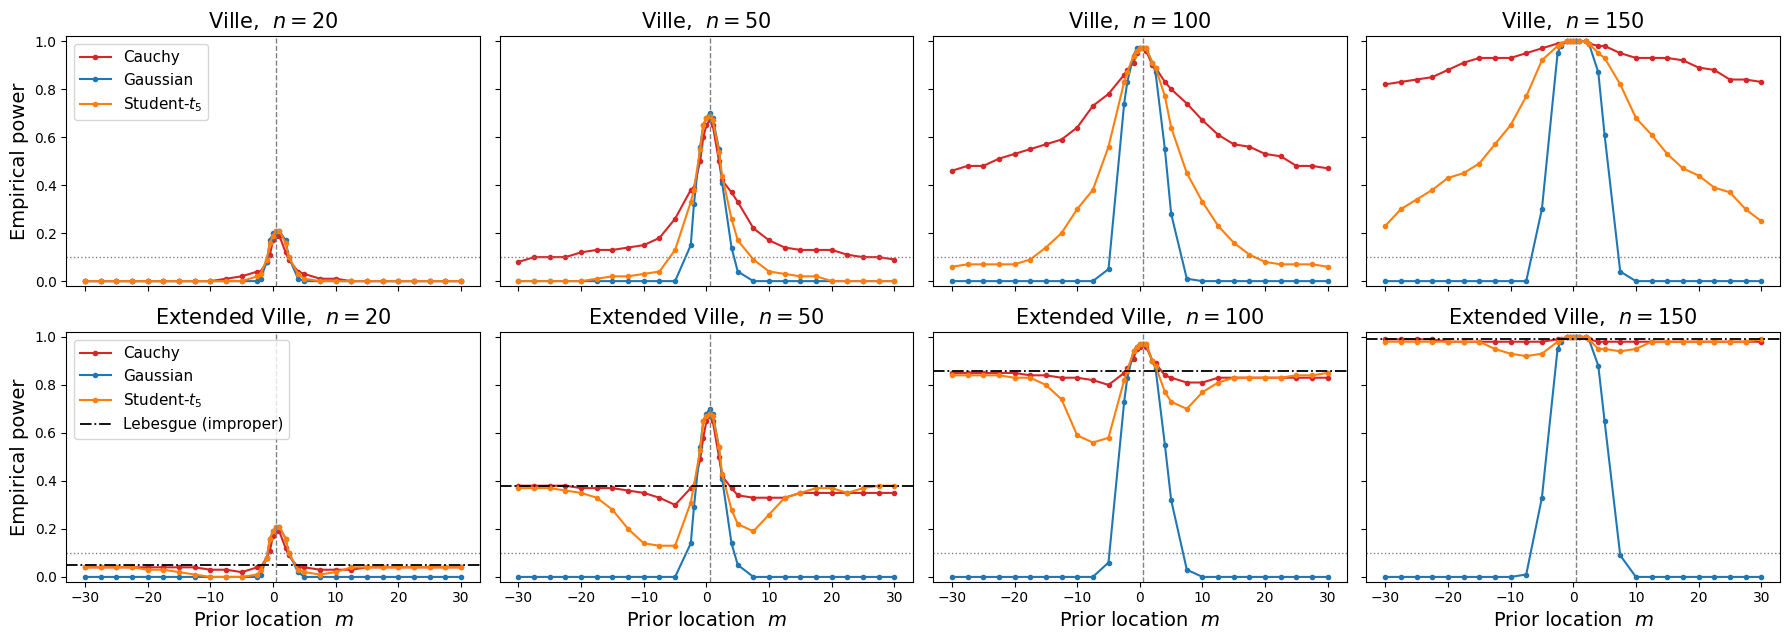

In [10]:
# =============================================================================
# CELL 9 — MAIN FIGURE 1 plot: power_vs_m_priors.pdf
# =============================================================================
fig, axes = plt.subplots(2, len(n_values), figsize=(4.5 * len(n_values), 6.5),
                         sharex=True, sharey=True)

for k, n in enumerate(n_values):
    ax = axes[0, k]                                  # Ville
    for prior_name in prior_names:
        ax.plot(m_grid, powers_V[(prior_name, n)], "-o", markersize=3,
                color=PRIOR_COLORS[prior_name], label=prior_name)
    ax.axvline(theta_star, color="gray", linestyle="--", linewidth=1)
    ax.axhline(alpha, color="gray", linestyle=":", linewidth=1)
    ax.set_title(f"Ville,  $n = {n}$", fontsize=15)
    ax.set_ylim(-0.02, 1.02)
    if k == 0:
        ax.set_ylabel("Empirical power", fontsize=14)
        ax.legend(loc="upper left", fontsize=11, frameon=True)

    ax = axes[1, k]                                  # extended Ville
    for prior_name in prior_names:
        ax.plot(m_grid, powers_eV[(prior_name, n)], "-o", markersize=3,
                color=PRIOR_COLORS[prior_name], label=prior_name)
    ax.axhline(leb_baseline[n], color="black", linestyle="-.", linewidth=1.3,
               label="Lebesgue (improper)")
    ax.axvline(theta_star, color="gray", linestyle="--", linewidth=1)
    ax.axhline(alpha, color="gray", linestyle=":", linewidth=1)
    ax.set_title(f"Extended Ville,  $n = {n}$", fontsize=15)
    ax.set_xlabel(r"Prior location  $m$", fontsize=14)
    ax.set_ylim(-0.02, 1.02)
    if k == 0:
        ax.set_ylabel("Empirical power", fontsize=14)
        ax.legend(loc="upper left", fontsize=11, frameon=True)

fig.tight_layout()
fig.savefig(f"{FIGDIR}/power_vs_m_priors.pdf", bbox_inches="tight")
plt.show()

Running p-value trajectories ...
  100 streams, 23 n-points (2..150),  ~11040 quad calls
  100 streams, n = 2..150 (149 evaluation points)
  tabulating A_n ...
  A_n tables done: 12.1s


/var/folders/31/6gx1txds1v51wc6_tdp16jth0000gp/T/ipykernel_58658/2012194725.py:25: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  integral, _ = quad(integrand, -theta_max, theta_max,
/var/folders/31/6gx1txds1v51wc6_tdp16jth0000gp/T/ipykernel_58658/2605514602.py:23: RuntimeWarning: divide by zero encountered in log
  + np.log(integral))


  Cauchy: 528.7s
  Gaussian: 1097.5s
  Student-$t_5$: 1693.8s


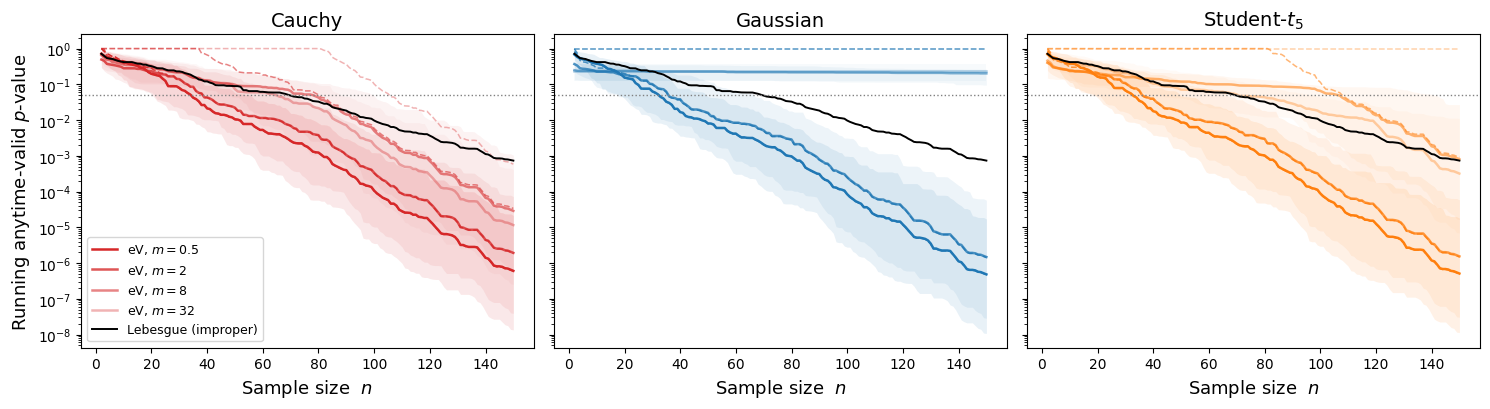

In [14]:
# =============================================================================
# CELL 10 — MAIN FIGURE 2: running anytime-valid p-value vs n
# =============================================================================
print("Running p-value trajectories ...")  # N_TRAJ_PTS = 60, NU_DATA = 120, B_data = 10_000, B_cal = 100_000 for actual run

ALPHA_TRAJ = 0.05                    # level for this figure
M_TRAJ     = [0.5, 2.0, 8.0, 32.0]   # prior locations: truth -> severe conflict
SUMMARY    = "median"                # "median" (with IQR band) or "mean"
N_STRIDE   = 1                       # raise to 2 or 5 to cut runtime 

N_TRAJ_PTS = 25                      # log-spaced evaluation points
NU_DATA    = 40                      # inner-loop u grid  (was 200)
NU_CAL     = 120                     # calibration grid   (do NOT shrink this)

# ---- log-spaced n grid ------------------------------------------------------
n_max_traj = Y_full.shape[1]
u_all = np.cumsum(Y_full, axis=1) / np.sqrt(np.cumsum(Y_full ** 2, axis=1))
ns_traj = np.unique(np.round(np.geomspace(2, n_max_traj, N_TRAJ_PTS)).astype(int))
u_traj_all = u_all[:, ns_traj - 1]
print(f"  {u_traj_all.shape[0]} streams, {len(ns_traj)} n-points "
      f"({ns_traj[0]}..{ns_traj[-1]}),  "
      f"~{len(ns_traj)*NU_DATA*len(M_TRAJ)*len(PRIOR_LOG_PDFS)} quad calls")


# ---- running u_n for every stream, reusing the Cell 8 data --------------------
n_max_traj = Y_full.shape[1]
u_all = np.cumsum(Y_full, axis=1) / np.sqrt(np.cumsum(Y_full ** 2, axis=1))
ns_traj = np.arange(2, n_max_traj + 1)[::N_STRIDE]
u_traj_all = u_all[:, ns_traj - 1]                      # (B_data, n_traj)
print(f"  {u_traj_all.shape[0]} streams, n = 2..{n_max_traj} "
      f"({len(ns_traj)} evaluation points)")

# ---- A_n tables for every n on the trajectory grid ---------------------------
print("  tabulating A_n ...")
t0 = time()
A_traj = {}
for n in ns_traj:
    n = int(n)
    A_traj[n] = make_log_A_n_table(
        n, z_max=(35.0 if n == 2 else 16.0),
        num_points=(1401 if n == 2 else 401))
print(f"  A_n tables done: {time() - t0:.1f}s")

# ---- exact extended-Ville calibration g(x) = E_0[min(M_2/x, 1)] --------------
def make_g_from_samples(M2_samples):
    """Exact calibration map from a null sample of M_2, vectorised in x.
       g(x) = P(M_2 >= x) + E[M_2 1{M_2 < x}]/x."""
    s = np.sort(np.asarray(M2_samples, dtype=float))
    c = np.concatenate([[0.0], np.cumsum(s)])
    N = s.size

    def g(x):
        x = np.atleast_1d(np.asarray(x, dtype=float))
        out = np.empty_like(x)
        pos = x > 0
        idx = np.searchsorted(s, x[pos], side="left")     # count of M_2 < x
        below_sum = c[idx]
        out[pos] = ((N - idx) + below_sum / x[pos]) / N
        out[~pos] = 1.0
        return np.minimum(out, 1.0)

    return g

# ---- Lebesgue baseline (closed form, no Monte Carlo error) -------------------
M_leb_all = np.exp(np.minimum(log_M_n_leb(u_traj_all, ns_traj[None, :]), 700.0))
p_leb_all = g_leb(np.maximum.accumulate(M_leb_all, axis=1))

# ---- trajectories, one (prior, m) at a time ---------------------------------
summ_eV, summ_V, band_eV = {}, {}, {}
t0 = time()
for prior_name, prior_log_pdf in PRIOR_LOG_PDFS.items():
    for m in M_TRAJ:
        # # exact calibration for this (prior, m)
        # ug2, lMg2 = precompute_log_M_n_on_u_grid(
        #     m=m, n=2, prior_log_pdf=prior_log_pdf,
        #     z_grid_n=z_grid_n2, log_A_grid_n=log_A_grid_n2, n_u=10) # was 200
        ug2, lMg2 = precompute_log_M_n_on_u_grid(
            m=m, n=2, prior_log_pdf=prior_log_pdf,
            z_grid_n=z_grid_n2, log_A_grid_n=log_A_grid_n2, n_u=NU_CAL)

        M2_cal = np.exp(np.minimum(
            eval_log_M(u2c, ug2, lMg2, m, 2, prior_log_pdf,
                       z_grid_n2, log_A_grid_n2), 700.0))
        g_m = make_g_from_samples(M2_cal)

        # wealth at every n, for every stream
        logM = np.empty_like(u_traj_all)
        # for j, n in enumerate(ns_traj):
        #     n = int(n)
        #     zg, lAg = A_traj[n]
        #     ug, lMg = precompute_log_M_n_on_u_grid(
        #         m=m, n=n, prior_log_pdf=prior_log_pdf,
        #         z_grid_n=zg, log_A_grid_n=lAg, n_u=200)
        #     logM[:, j] = eval_log_M(u_traj_all[:, j], ug, lMg, m, n,
        #                             prior_log_pdf, zg, lAg)
        for j, n in enumerate(ns_traj):
            n = int(n)
            zg, lAg = A_traj[n]
            lo, hi = u_traj_all[:, j].min(), u_traj_all[:, j].max()
            pad = 0.05 * max(hi - lo, 1e-3)
            cap = min(np.sqrt(n) - 1e-3, _u_cap(n, zg[-1]))
            ug = np.linspace(max(lo - pad, -cap), min(hi + pad, cap), NU_DATA)
            lMg = np.array([log_M_n_quad_single(u, m, n, prior_log_pdf, zg, lAg)
                            for u in ug])
            logM[:, j] = np.interp(u_traj_all[:, j], ug, lMg)

        M_run = np.maximum.accumulate(np.exp(np.minimum(logM, 700.0)), axis=1)

        p_V  = np.minimum(1.0, 1.0 / M_run)          # Ville
        p_eV = g_m(M_run.ravel()).reshape(M_run.shape)   # extended Ville, exact

        if SUMMARY == "median":
            summ_eV[(prior_name, m)] = np.median(p_eV, axis=0)
            summ_V[(prior_name, m)]  = np.median(p_V,  axis=0)
            band_eV[(prior_name, m)] = np.percentile(p_eV, [25, 75], axis=0)
        else:
            summ_eV[(prior_name, m)] = p_eV.mean(axis=0)
            summ_V[(prior_name, m)]  = p_V.mean(axis=0)
            band_eV[(prior_name, m)] = None

        del logM, M_run, p_V, p_eV
    print(f"  {prior_name}: {time() - t0:.1f}s")

p_leb_summ = (np.median(p_leb_all, axis=0) if SUMMARY == "median"
              else p_leb_all.mean(axis=0))

# ---- plot -------------------------------------------------------------------
fig, axes = plt.subplots(1, len(prior_names),
                         figsize=(5.0 * len(prior_names), 4.2),
                         sharex=True, sharey=True)

for k, prior_name in enumerate(prior_names):
    ax = axes[k]
    shades = np.linspace(0.35, 1.0, len(M_TRAJ))[::-1]
    base = PRIOR_COLORS[prior_name]
    for s, m in zip(shades, M_TRAJ):
        if band_eV[(prior_name, m)] is not None:
            lo, hi = band_eV[(prior_name, m)]
            ax.fill_between(ns_traj, lo, hi, color=base, alpha=0.10 * s,
                            linewidth=0)
        ax.plot(ns_traj, summ_eV[(prior_name, m)], "-", color=base,
                alpha=s, linewidth=1.8, label=fr"eV, $m={m:g}$")
        ax.plot(ns_traj, summ_V[(prior_name, m)], "--", color=base,
                alpha=s, linewidth=1.1)
    ax.plot(ns_traj, p_leb_summ, color="black", linewidth=1.4,
            label="Lebesgue (improper)")
    ax.axhline(ALPHA_TRAJ, color="gray", linestyle=":", linewidth=1)
    ax.set_yscale("log")
    ax.set_xlabel(r"Sample size  $n$", fontsize=13)
    ax.set_title(prior_name, fontsize=14)
    if k == 0:
        ax.set_ylabel(r"Running anytime-valid $p$-value", fontsize=13)
        ax.legend(loc="lower left", fontsize=9, frameon=True, ncol=1)

fig.tight_layout()
fig.savefig(f"{FIGDIR}/pvalue_vs_n_simulated.pdf", bbox_inches="tight")
plt.show()